# Daubechies Wavelet Decomposition: 1-Level Analysis

This notebook demonstrates a 1-level Daubechies (db2) wavelet decomposition of an image, visualizing the approximation and detail coefficients, similar to the Haar analysis.

In [2]:
# Import Required Libraries
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.image import imread
import pywt
import os

## Load and Convert Image to Grayscale

We load the image and convert it to grayscale for wavelet analysis.

In [3]:
# Load and convert image to grayscale
A = imread(os.path.join('..','DATA','dog.jpg'))
B = np.mean(A, -1)  # Convert RGB to grayscale

## Perform 1-Level Daubechies Wavelet Decomposition

We use the Daubechies (db2) wavelet to decompose the grayscale image into approximation and detail coefficients.

In [4]:
# Perform 1-level Daubechies (db2) wavelet decomposition
coeffs2 = pywt.dwt2(B, 'db2')
cA, (cH, cV, cD) = coeffs2

## Visualize Approximation and Detail Coefficients

The following cell visualizes the approximation and detail coefficients (horizontal, vertical, diagonal) from the first level of Daubechies (db2) wavelet decomposition.

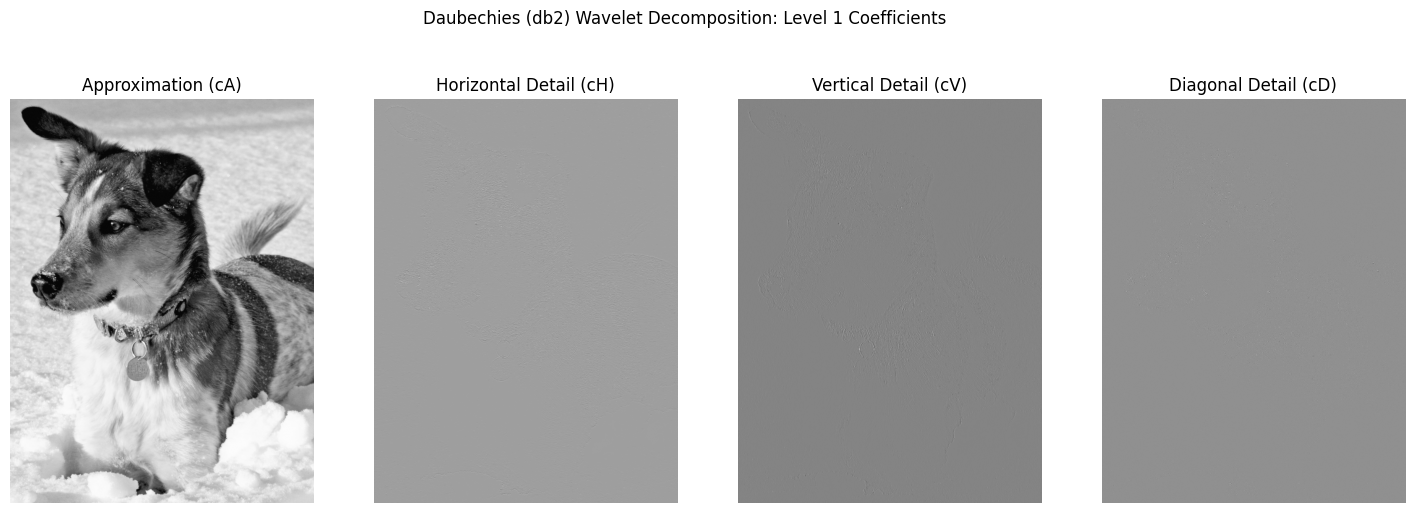

In [5]:
# Plot the coefficients
fig, axs = plt.subplots(1, 4, figsize=(18, 6))
axs[0].imshow(cA, cmap='gray')
axs[0].set_title('Approximation (cA)')
axs[0].axis('off')
axs[1].imshow(cH, cmap='gray')
axs[1].set_title('Horizontal Detail (cH)')
axs[1].axis('off')
axs[2].imshow(cV, cmap='gray')
axs[2].set_title('Vertical Detail (cV)')
axs[2].axis('off')
axs[3].imshow(cD, cmap='gray')
axs[3].set_title('Diagonal Detail (cD)')
axs[3].axis('off')
plt.suptitle('Daubechies (db2) Wavelet Decomposition: Level 1 Coefficients')
plt.show()

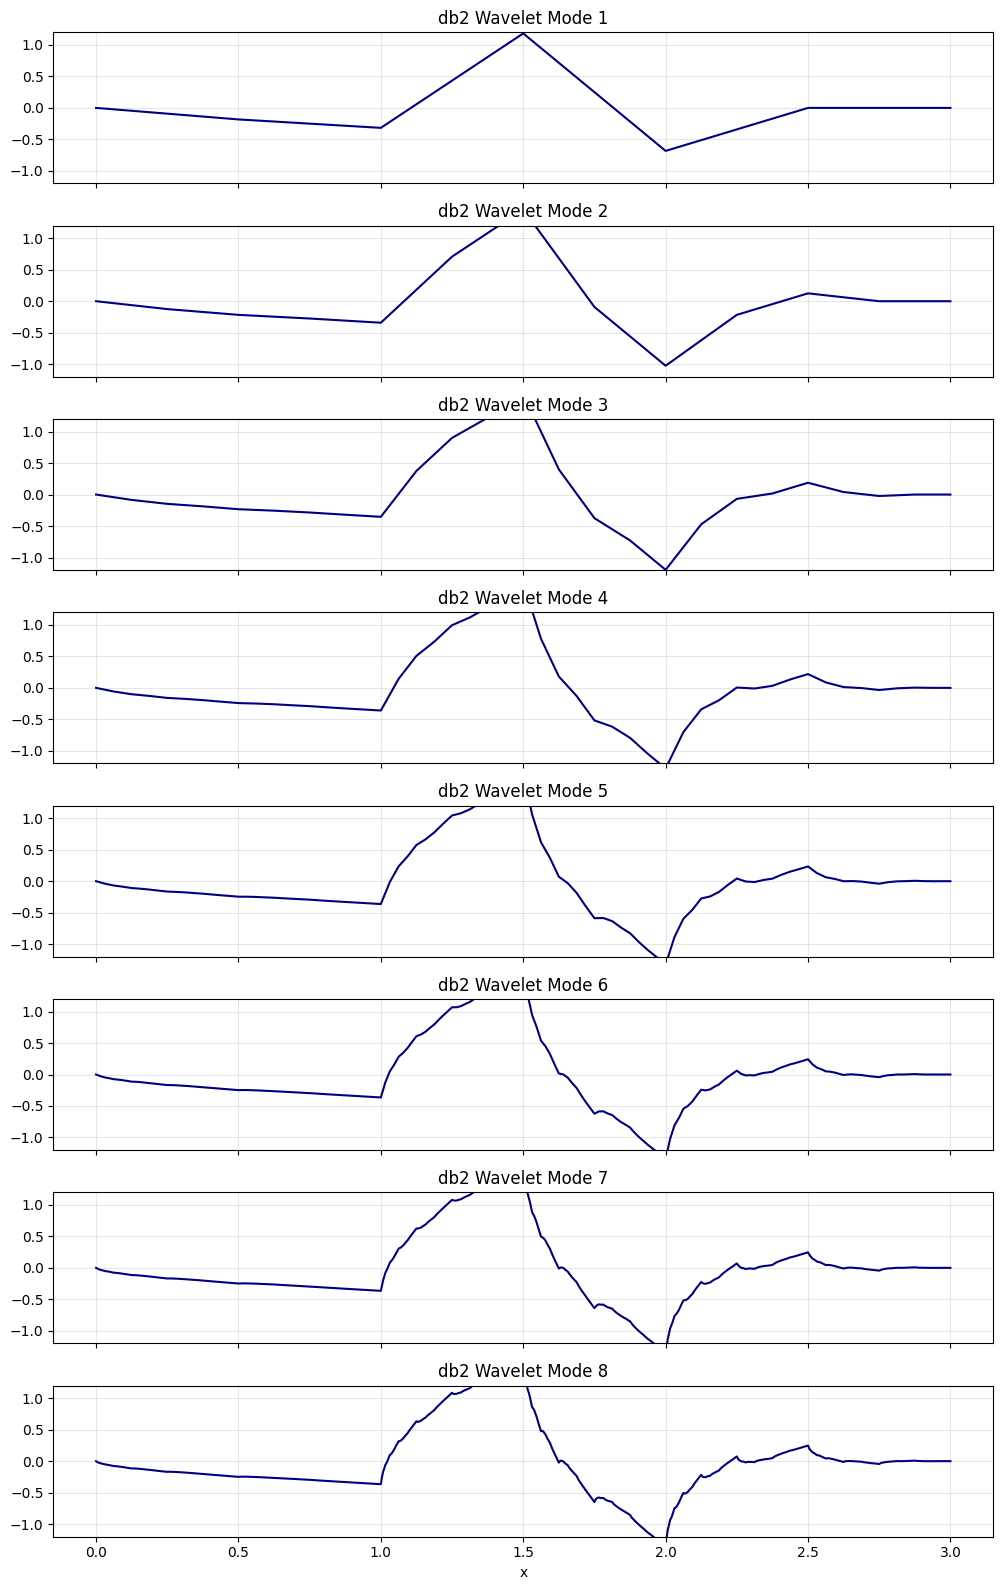

In [6]:
# Plot the first 8 Daubechies (db2) wavelet modes
import pywt

wavelet = pywt.Wavelet('db2')
max_level = 8
length = 1024  # Length for visualization

fig, axs = plt.subplots(max_level, 1, figsize=(10, 16), sharex=True)

for i in range(1, max_level + 1):
    # Get the wavelet function (scaling and wavelet)
    phi, psi, x = wavelet.wavefun(level=i)
    axs[i-1].plot(x, psi, color='navy')
    axs[i-1].set_title(f'db2 Wavelet Mode {i}')
    axs[i-1].set_ylim(-1.2, 1.2)
    axs[i-1].grid(True, alpha=0.3)

axs[-1].set_xlabel('x')
plt.tight_layout()
plt.show()

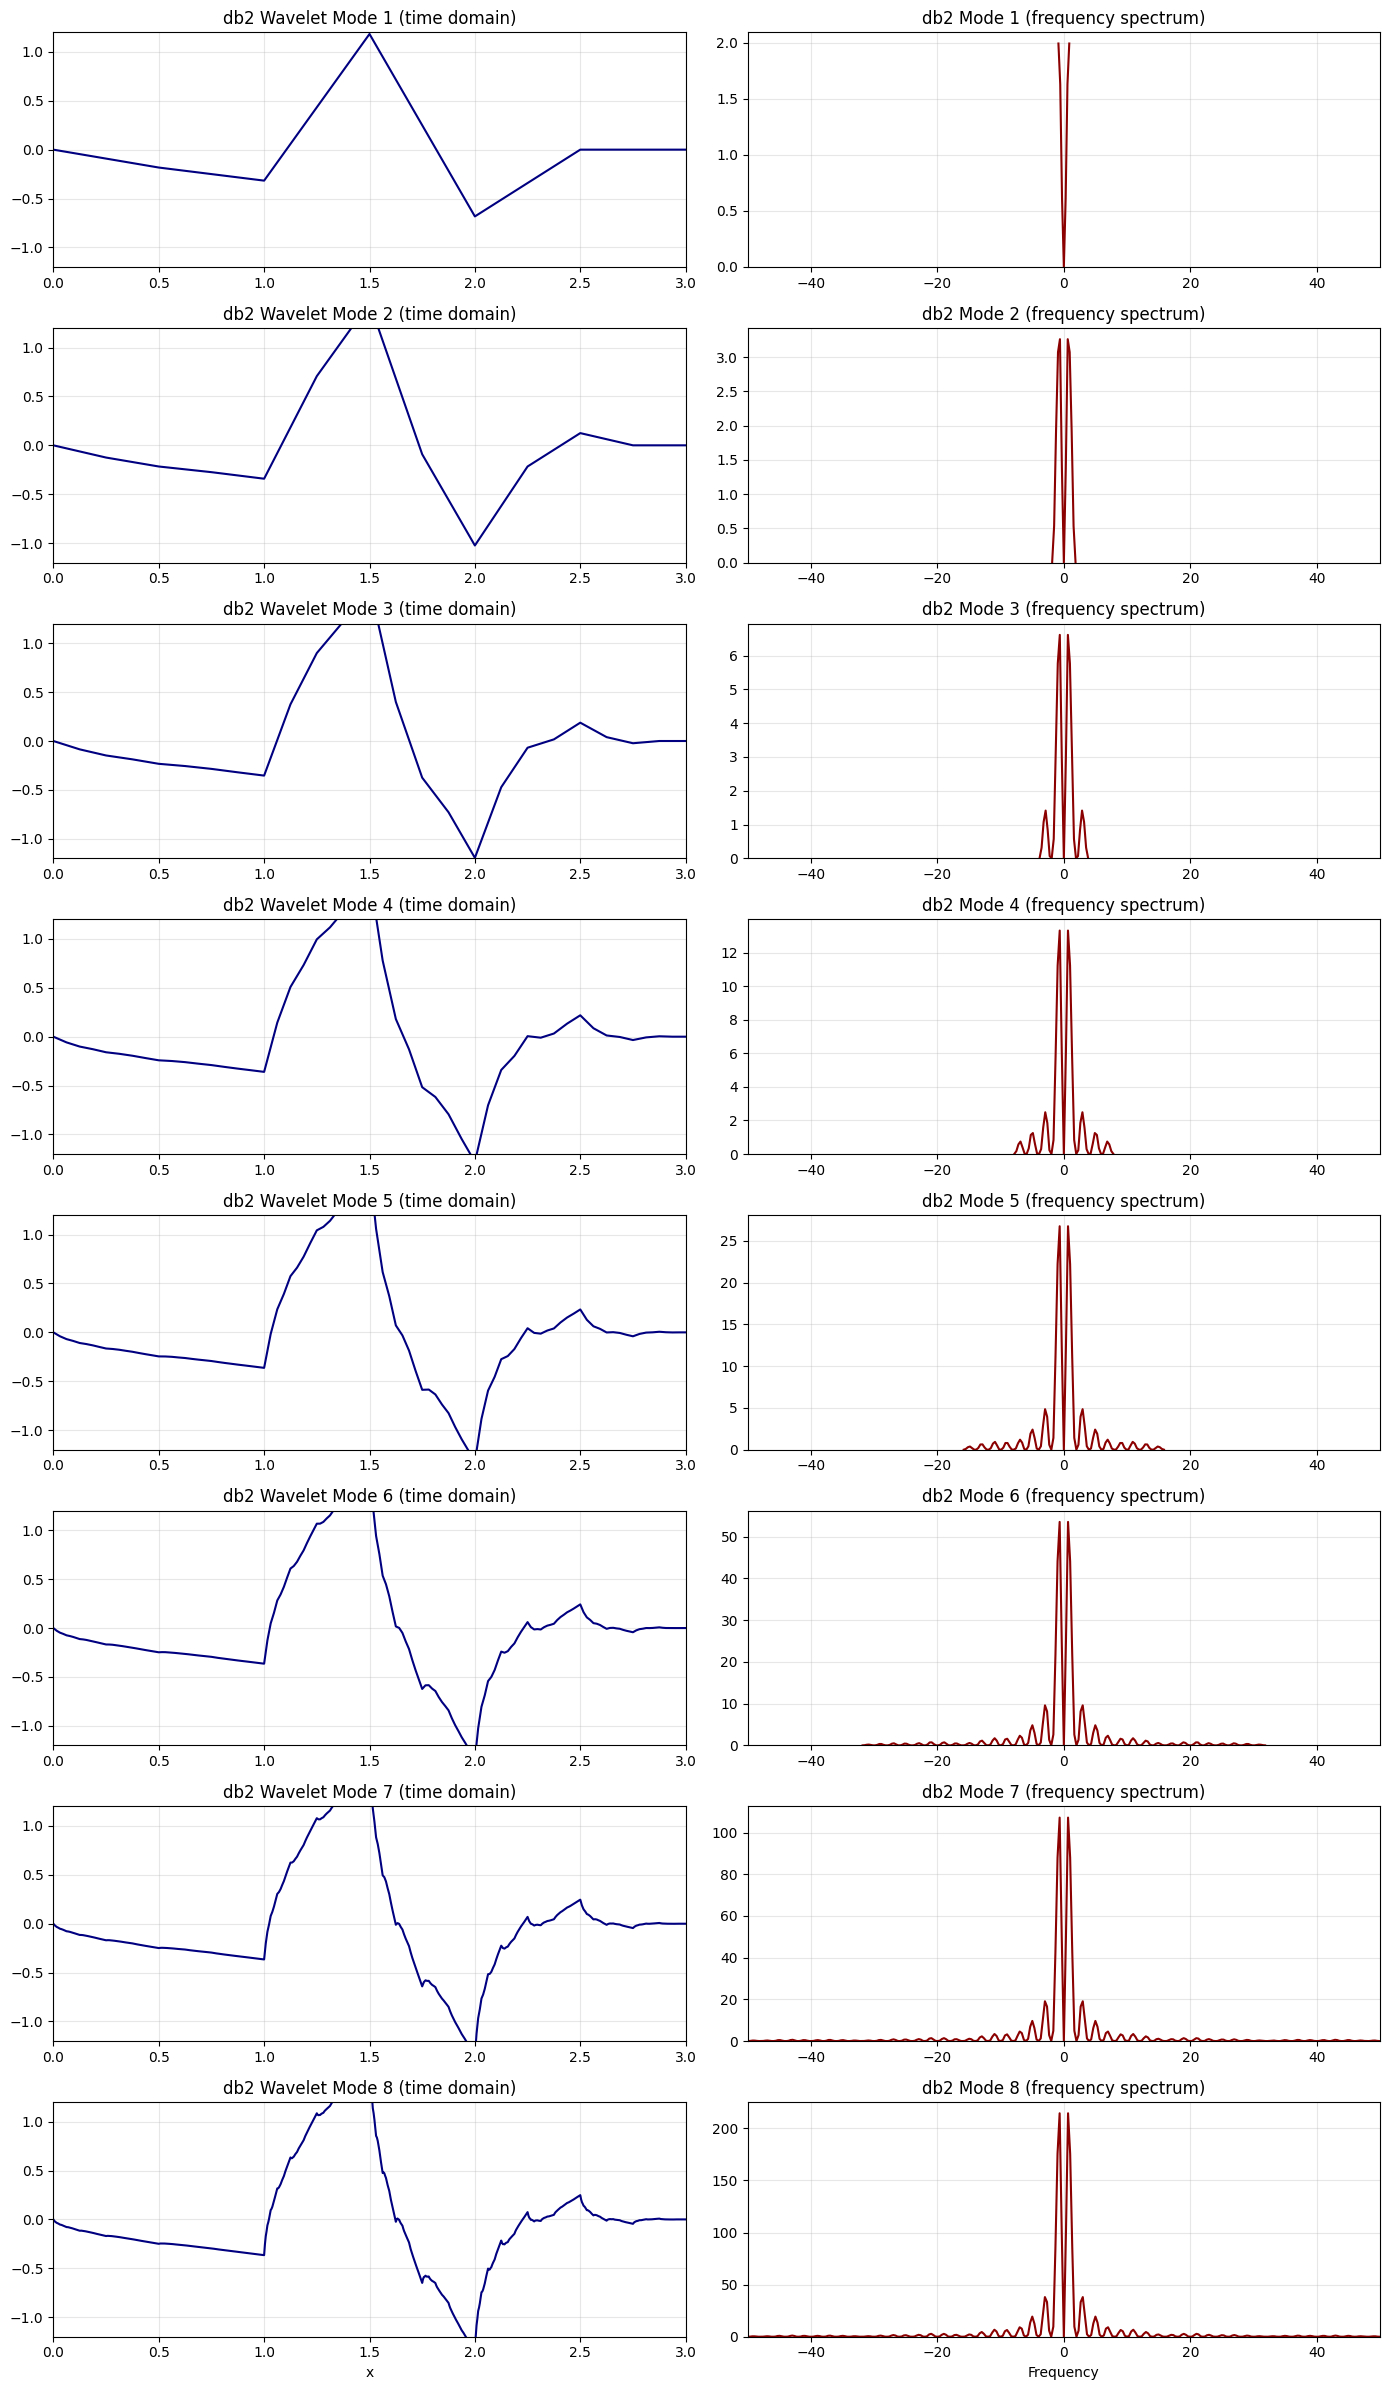

In [7]:
# Plot the frequency spectrum for each of the first 8 Daubechies (db2) wavelet modes
from numpy.fft import fft, fftfreq, fftshift

fig, axs = plt.subplots(8, 2, figsize=(14, 24))
wavelet = pywt.Wavelet('db2')

for i in range(1, 9):
    phi, psi, x = wavelet.wavefun(level=i)
    # Time domain plot
    axs[i-1, 0].plot(x, psi, color='navy')
    axs[i-1, 0].set_title(f'db2 Wavelet Mode {i} (time domain)')
    axs[i-1, 0].set_xlim(x[0], x[-1])
    axs[i-1, 0].set_ylim(-1.2, 1.2)
    axs[i-1, 0].grid(True, alpha=0.3)
    # Frequency domain plot
    n = len(psi)
    dx = x[1] - x[0]
    W = fft(psi)
    freqs = fftfreq(n, d=dx)
    W_shifted = fftshift(W)
    freqs_shifted = fftshift(freqs)
    axs[i-1, 1].plot(freqs_shifted, np.abs(W_shifted), color='darkred')
    axs[i-1, 1].set_title(f'db2 Mode {i} (frequency spectrum)')
    axs[i-1, 1].set_xlim(-50, 50)
    axs[i-1, 1].set_ylim(0, None)
    axs[i-1, 1].grid(True, alpha=0.3)

axs[-1, 0].set_xlabel('x')
axs[-1, 1].set_xlabel('Frequency')
plt.tight_layout()
plt.show()

## Orthogonality and Time/Frequency Localization of Daubechies vs Haar Wavelets

- **Orthogonality:**
    - Both Haar and Daubechies (db2) wavelets are orthogonal. This means the inner product (integral of the product) of different modes is zero:
      $$
      \langle \psi_i, \psi_j \rangle = 0 \quad \text{for } i \neq j
      $$
    - This property ensures that each wavelet mode captures unique information, with no redundancy.

- **Time/Frequency Localization Chart:**
    - The chart below summarizes the localization properties of Haar and Daubechies wavelets.

| Wavelet Type | Time Localization | Frequency Localization | Smoothness | Support |
|--------------|-------------------|-----------------------|------------|---------|
| Haar         | Excellent (compact, sharp edges) | Poor (broad spectrum, many frequencies) | Discontinuous | Shortest (2 samples) |
| Daubechies (db2) | Good (compact, smoother edges) | Better than Haar (more concentrated) | Continuous, not differentiable | Short (4 samples) |

- **Comparison:**
    - **Haar:** Best for detecting sharp changes (edges), but poor frequency localization due to discontinuity.
    - **Daubechies (db2):** Smoother, better frequency localization, captures oscillatory features more efficiently, but slightly less localized in time.

---

### Visual Comparison
- The time-domain plots show Haar wavelets are blocky and abrupt, while Daubechies wavelets are smoother.
- The frequency spectra show Daubechies wavelets have less energy at high frequencies compared to Haar, indicating better frequency localization.

**Summary:**
- Both are orthogonal and compactly supported.
- Haar is best for sharp, local features; Daubechies is better for smooth, oscillatory features and frequency analysis.

## How Daubechies Wavelets Achieve Time Localization

- **Time localization** is achieved by:
  - The wavelet being nonzero only in a small region (compact support).
  - The oscillatory nature (positive and negative lobes) causing cancellation, so the wavelet “detects” local features and changes.
  - The mean-zero property (integral of the wavelet is zero) ensures the wavelet ignores constant or slowly varying parts of the signal, focusing on local changes.

### Visual Example: Cancellation and Localization
The plot below shows a Daubechies (db2) wavelet and highlights its positive and negative lobes. The sum of the area under the curve is zero, illustrating how the wavelet is localized and sensitive to changes in a small region.

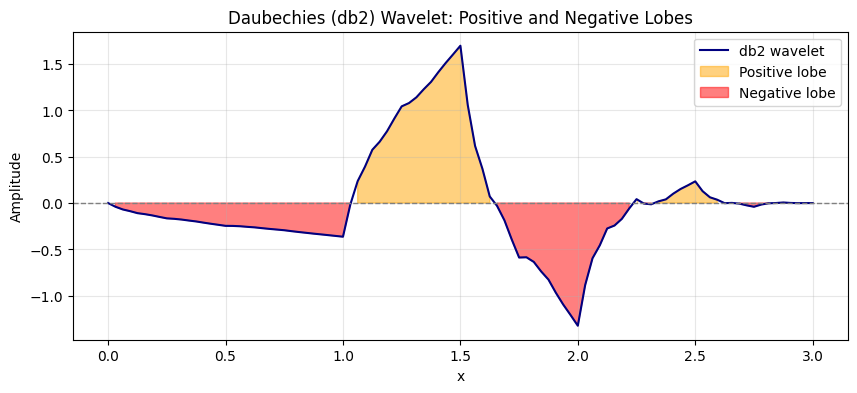

Sum (approximate integral) of wavelet: -7.128629284092192e-18


In [8]:
# Visual example: db2 wavelet, positive/negative lobes, and mean-zero property
wavelet = pywt.Wavelet('db2')
phi, psi, x = wavelet.wavefun(level=5)

plt.figure(figsize=(10, 4))
plt.plot(x, psi, label='db2 wavelet', color='navy')
plt.fill_between(x, psi, 0, where=(psi > 0), color='orange', alpha=0.5, label='Positive lobe')
plt.fill_between(x, psi, 0, where=(psi < 0), color='red', alpha=0.5, label='Negative lobe')
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Daubechies (db2) Wavelet: Positive and Negative Lobes')
plt.xlabel('x')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Show that the integral (sum) is approximately zero
print('Sum (approximate integral) of wavelet:', np.sum(psi) * (x[1] - x[0]))

## Why Daubechies Wavelets Are Smooth but Not Continuous

- **Daubechies wavelets (db2 and higher) are continuous functions**: There are no jumps or discontinuities in their values.
- **However, they are not differentiable everywhere**: Their derivatives are not continuous; there are “kinks” or points where the slope changes abruptly.
- This property is called being **continuous but not differentiable** (or not smooth in the strict mathematical sense).
- As you use higher-order Daubechies wavelets (dbN with larger N), the wavelets become smoother (more continuous derivatives).

**Summary:**
- db2 is continuous, but its derivative is not.
- db3 is once differentiable, db4 is twice differentiable, etc.
- This increasing smoothness is a key advantage of Daubechies wavelets over Haar, which is discontinuous.